# Experiment 7: Time Series Analysis of Stock Data

**A52 Dipanshu Ambilkar**

In [1]:
# A52 Dipanshu Ambilkar
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

In [2]:
np.random.seed(6)
dates = pd.date_range("2025-01-01", periods=240)
price = 100 + np.cumsum(np.random.normal(0.3, 2, 240))
df = pd.DataFrame({
    "date": dates,
    "close": np.round(price, 2),
    "volume": np.random.randint(100000, 900000, 240),
})
print(df.head())
print(df.shape)

        date   close  volume
0 2025-01-01   99.68  592896
1 2025-01-02  101.43  231931
2 2025-01-03  102.17  751394
3 2025-01-04  100.67  260365
4 2025-01-05   96.00  420685
(240, 3)


In [3]:
df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")

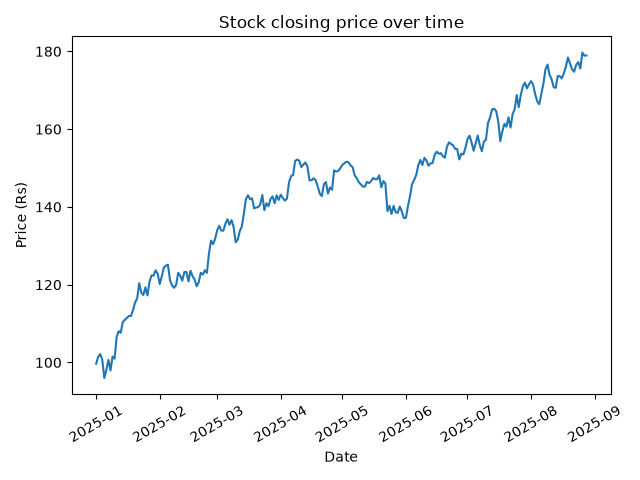

In [4]:
plt.plot(df.index, df["close"])
plt.title("Stock closing price over time")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("stock_trend.png")
display(Image("stock_trend.png"))
plt.close()

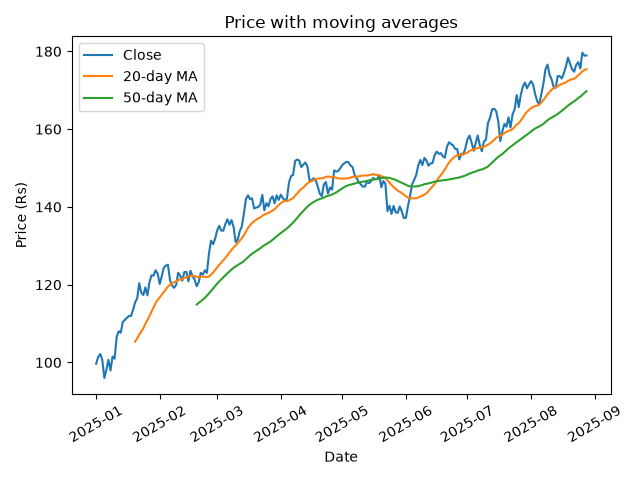

In [5]:
df["ma20"] = df["close"].rolling(20).mean()
df["ma50"] = df["close"].rolling(50).mean()
plt.plot(df.index, df["close"], label="Close")
plt.plot(df.index, df["ma20"], label="20-day MA")
plt.plot(df.index, df["ma50"], label="50-day MA")
plt.title("Price with moving averages")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("stock_ma.png")
display(Image("stock_ma.png"))
plt.close()

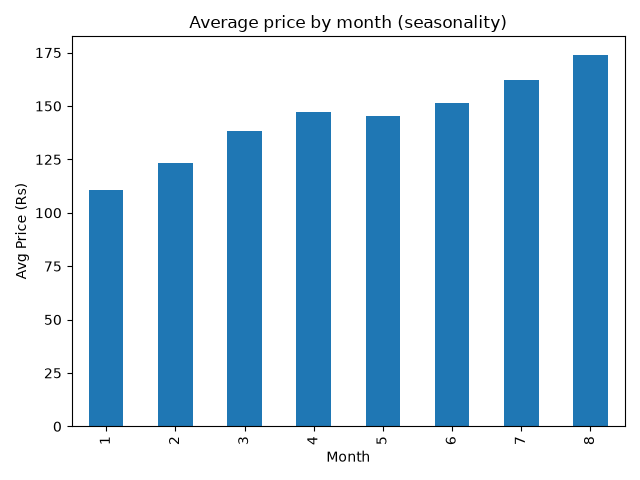

In [6]:
df["month"] = df.index.month
monthly = df.groupby("month")["close"].mean()
monthly.plot(kind="bar")
plt.title("Average price by month (seasonality)")
plt.xlabel("Month")
plt.ylabel("Avg Price (Rs)")
plt.tight_layout()
plt.savefig("stock_season.png")
display(Image("stock_season.png"))
plt.close()

price-volume correlation: -0.03790653641231994


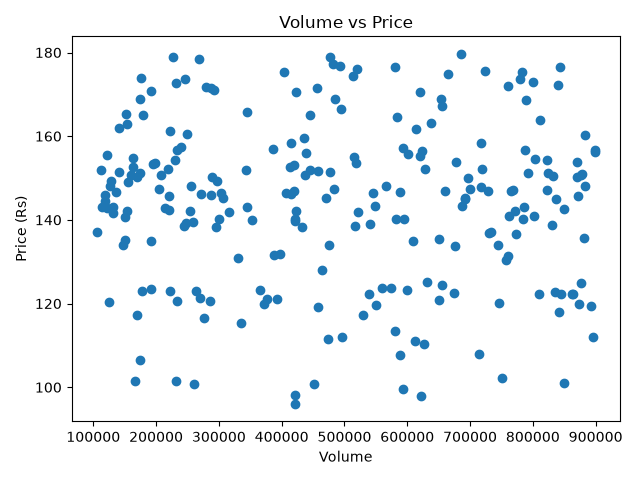

In [7]:
print("price-volume correlation:", df["close"].corr(df["volume"]))
plt.scatter(df["volume"], df["close"])
plt.title("Volume vs Price")
plt.xlabel("Volume")
plt.ylabel("Price (Rs)")
plt.tight_layout()
plt.savefig("stock_corr.png")
display(Image("stock_corr.png"))
plt.close()

In [8]:
alpha = 0.3
s = [df["close"].iloc[0]]
for p in df["close"].iloc[1:]:
    s.append(alpha * p + (1 - alpha) * s[-1])
df["forecast"] = s
future = pd.date_range(df.index[-1] + pd.Timedelta(days=1), periods=30)
last = s[-1]
trend = (s[-1] - s[-30]) / 30
fp = [last + trend * i for i in range(1, 31)]

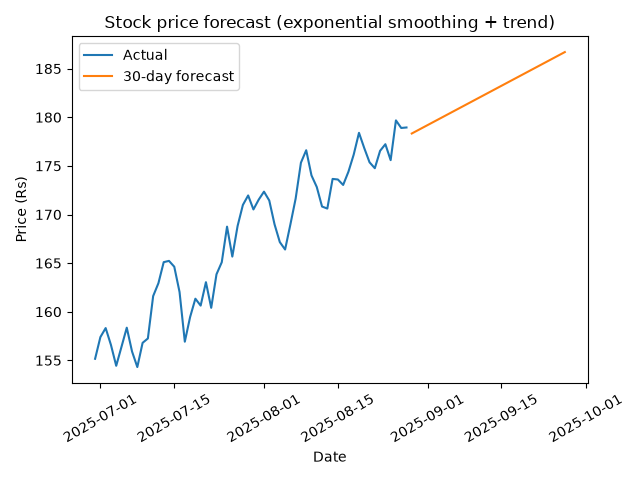

done


In [9]:
plt.plot(df.index[-60:], df["close"][-60:], label="Actual")
plt.plot(future, fp, label="30-day forecast")
plt.title("Stock price forecast (exponential smoothing + trend)")
plt.xlabel("Date")
plt.ylabel("Price (Rs)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("stock_forecast.png")
display(Image("stock_forecast.png"))
plt.close()
print("done")